# HSQC 交叉峰预测

根据已知分子结构与溶剂预测碳氢交叉峰。

加载 TransPeakNet 作者权重，按输入 SMILES 的顺序补氢建图。对每个碳位点，按原子编号将模型的碳输出和两个有序氢输出与专家标注配对。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.hsqc.transpeaknet')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.hsqc.transpeaknet
Examples: 1


## 输入与输出

| Field | Meaning |
| --- | --- |
| `smiles` | 保留原子顺序的已知结构。 |
| `solvent` | 作者定义的九种溶剂类别之一。 |

| Field | Meaning |
| --- | --- |
| `carbon_atom_index` | 带氢碳原子的编号，从零开始。 |
| `carbon_ppm / proton_ppm` | 各碳位点的碳位移及两个氢位移输出，单位为 ppm。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "sample_id": "32869.csv",
  "input": {
    "smiles": "CCCC#N",
    "solvent": "CDCl3"
  },
  "output": {
    "peaks_c_h_ppm": [
      [
        12.845844268798828,
        0.962708592414856
      ],
      [
        18.62872314453125,
        1.6068708896636963
      ],
      [
        19.271541595458984,
        2.4061617851257324
      ]
    ],
    "carbon_atom_index": [
      0,
      1,
      2
    ]
  },
  "reference": {
    "peaks_c_h_ppm": [
      [
        13.3,
        1.081
      ],
      [
        19.04,
        1.699
      ],
      [
        19.26,
        2.339
      ]
    ]
  }
}


## 评估预测

全量评测对 479 张谱等权平均。作者笔记本对溶剂表中的 511 行等权平均，覆盖 472 张谱。全量评测将 38 张有多种溶剂类别和 7 张缺溶剂记录的谱设为 unknown。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| 479 expert spectra | recorded model | carbon_mae_ppm | 2.02753 |
| 479 expert spectra | recorded model | proton_mae_ppm | 0.165891 |
| Author notebook (511 solvent rows) | recorded model | carbon_mae_ppm | 2.02487 |
| Author notebook (511 solvent rows) | recorded model | proton_mae_ppm | 0.165062 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 2,
  "real_examples": 1
}


## 查看结果图

丁腈在 CDCl₃ 中的实测和预测 HSQC 交叉峰。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

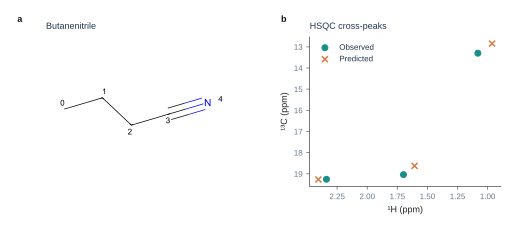

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.hsqc.transpeaknet', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.hsqc.transpeaknet --transpeaknet-source /path/to/2dNMR --limit 8 --output results/nmr-hsqc-transpeaknet.json
```

[Task](../tasks/nmr-hsqc-transpeaknet.md) · [Quick start](../quickstart.md)



## 参考文献

- Li, Y., Xu, H., et al. TransPeakNet for solvent-aware 2D NMR prediction via multi-task pre-training and unsupervised learning. Communications Chemistry (2025). [Source](https://doi.org/10.1038/s42004-025-01455-9)
